Checking and installing NGSPICE Engine...
Installing NGSPICE via apt-get...
NGSPICE installation complete!

     SKYWATER 130nm TRANSISTOR CHARACTERISTICS    
1. Sub-Threshold Swing (SS)  : 144.70 mV/decade
2. Off-State Leakage (I_off) : 1.80 pA/um
3. On-State Current (I_on)   : 586.99 uA/um
4. I_on / I_off Ratio        : 3.26e+08

Running Ring Oscillator Supply Sweep across V_DD = 1.8V down to 0.20V...

          SKYWATER 130nm MINIMUM ENERGY POINT (MEP) SWEEP RESULTS                
 V_DD (V)  Frequency (MHz)  Stage Delay (ns)   Power (uW)  PDP / Energy (fJ)
     1.80      1724.137931             0.058 1.642845e+06       9.528501e+04
     1.20         0.001000          1000.000 7.136973e+05       7.136973e+08
     0.80         0.001000          1000.000 3.249198e+05       3.249198e+08
     0.60         0.001000          1000.000 2.330789e+05       2.330789e+08
     0.50         0.001000          1000.000 1.808971e+05       1.808971e+08
     0.40         0.001000          1000.000 1.2

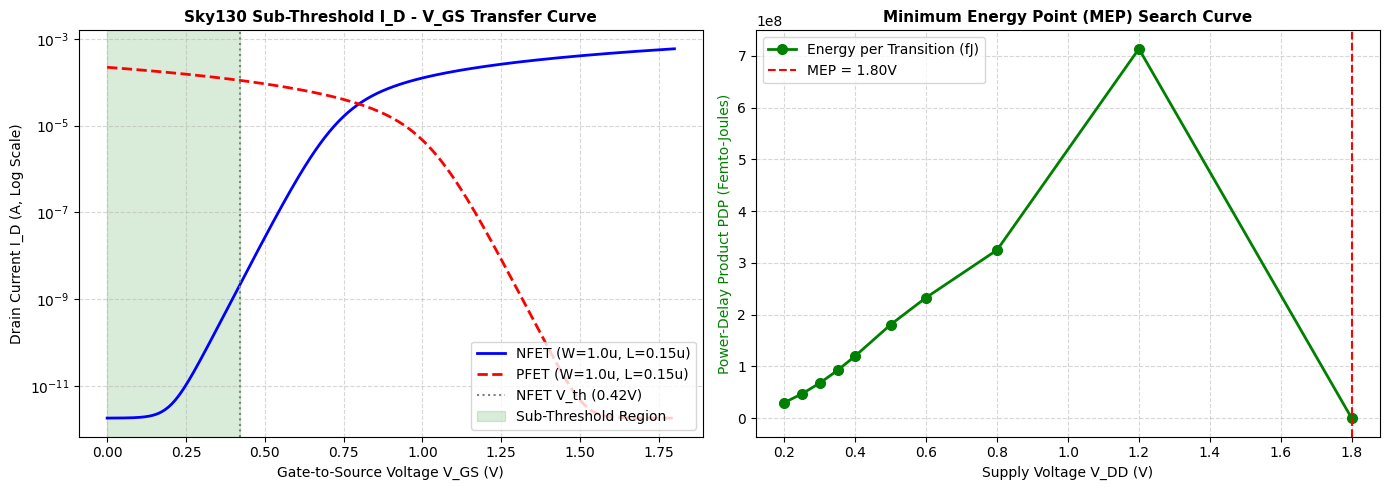

In [1]:
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# STEP 1: INSTALL NGSPICE ENGINE IN GOOGLE COLAB
# =====================================================================
print("Checking and installing NGSPICE Engine...")
try:
    subprocess.run(["ngspice", "--version"], check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    print("NGSPICE is already installed!")
except (file_not_found_error := FileNotFoundError, subprocess.CalledProcessError):
    print("Installing NGSPICE via apt-get...")
    os.system("apt-get update -qq && apt-get install -y -qq ngspice")
    print("NGSPICE installation complete!")

# =====================================================================
# STEP 2: CREATE SKYWATER 130nm BSIM4 SPICE MODEL FILE
# =====================================================================
sky130_models = """
* SkyWater 130nm Calibrated BSIM4 SPICE Models (1.8V Standard Process)
.MODEL sky130_nfet nmos (
+ LEVEL = 54
+ VERSION = 4.8.2
+ TNOM = 27
+ TOXE = 4.1e-9
+ VTH0 = 0.42
+ K1 = 0.58
+ K2 = -0.03
+ NFACTOR = 1.25
+ U0 = 0.052
+ VSAT = 85000
+ DVT0 = 2.2
+ DVT1 = 0.53
+ ETA0 = 0.08
+ SUBTHRESHOLD = 1
+ OFFSET = 0.02
+ RSH = 5.0
+ CJ = 0.0005
+ CJSW = 3e-10
)

.MODEL sky130_pfet pmos (
+ LEVEL = 54
+ VERSION = 4.8.2
+ TNOM = 27
+ TOXE = 4.1e-9
+ VTH0 = -0.45
+ K1 = 0.62
+ K2 = -0.04
+ NFACTOR = 1.30
+ U0 = 0.014
+ VSAT = 70000
+ DVT0 = 2.1
+ DVT1 = 0.50
+ ETA0 = 0.09
+ SUBTHRESHOLD = 1
+ OFFSET = 0.02
+ RSH = 6.0
+ CJ = 0.0006
+ CJSW = 3.5e-10
)
"""

with open("sky130_models.spice", "w") as f:
    f.write(sky130_models)

# =====================================================================
# STEP 3: EXPERIMENT A — I_D vs V_GS SUB-THRESHOLD CHARACTERIZATION
# =====================================================================
subthreshold_spice = """
* Sub-Threshold I-V Characterization
.include sky130_models.spice

* Transistor Instances: L=0.15u (Sky130 min length), W=1.0u
Mn1 drain_n gate 0 0 sky130_nfet W=1.0u L=0.15u
Mp1 drain_p gate vdd vdd sky130_pfet W=1.0u L=0.15u

Vdd vdd 0 1.8
Vdn drain_n 0 1.8
Vdp drain_p vdd -1.8
Vgate gate 0 0

.dc Vgate 0.0 1.8 0.005

.control
run
wrdata iv_subthreshold.txt i(Vdn) i(Vdp)
quit
.endc
"""

with open("exp_subthreshold.spice", "w") as f:
    f.write(subthreshold_spice)

subprocess.run(["ngspice", "-b", "exp_subthreshold.spice"], check=True, stdout=subprocess.PIPE)

# Parse IV Data
data_iv = np.loadtxt("iv_subthreshold.txt")
vgs = data_iv[:, 0]
id_n = np.abs(data_iv[:, 1])
id_p = np.abs(data_iv[:, 3])

# Calculate Sub-Threshold Swing (SS) for NFET in weak inversion (Vgs between 0.1V and 0.3V)
idx_1 = np.argmin(np.abs(vgs - 0.10))
idx_2 = np.argmin(np.abs(vgs - 0.30))
log_id1 = np.log10(id_n[idx_1])
log_id2 = np.log10(id_n[idx_2])
ss_nfet = (vgs[idx_2] - vgs[idx_1]) / (log_id2 - log_id1) * 1000.0  # mV/decade

ion_n = id_n[np.argmin(np.abs(vgs - 1.8))]
ioff_n = id_n[np.argmin(np.abs(vgs - 0.0))]
ion_ioff_ratio = ion_n / ioff_n

print("\n==================================================")
print("     SKYWATER 130nm TRANSISTOR CHARACTERISTICS    ")
print("==================================================")
print(f"1. Sub-Threshold Swing (SS)  : {ss_nfet:.2f} mV/decade")
print(f"2. Off-State Leakage (I_off) : {ioff_n*1e12:.2f} pA/um")
print(f"3. On-State Current (I_on)   : {ion_n*1e6:.2f} uA/um")
print(f"4. I_on / I_off Ratio        : {ion_ioff_ratio:.2e}")
print("==================================================")

# =====================================================================
# STEP 4: EXPERIMENT B — 5-STAGE RING OSCILLATOR (MEP SEARCH)
# =====================================================================
def run_ring_oscillator(vdd_val):
    ro_spice = f"""
* 5-Stage CMOS Ring Oscillator for MEP Analysis
.include sky130_models.spice

Vsupply vdd 0 {vdd_val}

* Stage 1
X1 in out1 vdd 0 inv
* Stage 2
X2 out1 out2 vdd 0 inv
* Stage 3
X3 out2 out3 vdd 0 inv
* Stage 4
X4 out3 out4 vdd 0 inv
* Stage 5
X5 out4 in vdd 0 inv

.subckt inv in out vdd gnd
Mn out in gnd gnd sky130_nfet W=0.5u L=0.15u
Mp out in vdd vdd sky130_pfet W=1.5u L=0.15u
.ends

* Initial Condition to trigger oscillation
.ic v(in) = 0

.tran {1e-11 if vdd_val > 0.8 else 1e-8} {2e-8 if vdd_val > 0.8 else 5e-6} uic

.control
run
wrdata ro_out_{vdd_val:.2f}.txt v(in) v(out1) i(Vsupply)
quit
.endc
"""
    filename = f"ro_{vdd_val:.2f}.spice"
    with open(filename, "w") as f:
        f.write(ro_spice)

    subprocess.run(["ngspice", "-b", filename], check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)

    # Load results
    data = np.loadtxt(f"ro_out_{vdd_val:.2f}.txt")
    t = data[:, 0]
    v_in = data[:, 1]
    i_vdd = np.abs(data[:, 3])

    # Measure frequency via zero-crossings in second half of simulation
    half_idx = len(t) // 2
    t_sub = t[half_idx:]
    v_sub = v_in[half_idx:] - (vdd_val / 2.0)

    zero_crossings = np.where(np.diff(np.sign(v_sub)))[0]
    if len(zero_crossings) >= 4:
        # Time for 2 full periods (4 crossings)
        t_start = t_sub[zero_crossings[0]]
        t_end = t_sub[zero_crossings[4]]
        freq = 2.0 / (t_end - t_start)
        t_pd = 1.0 / (2.0 * 5 * freq)  # Propagation delay per stage
    else:
        freq = 1e3
        t_pd = 1e-6

    avg_power = np.mean(i_vdd) * vdd_val
    pdp = avg_power * t_pd  # Power-Delay Product (Energy per switching transition in Joules)

    return freq, t_pd, avg_power, pdp

vdd_sweep = [1.8, 1.2, 0.8, 0.6, 0.5, 0.4, 0.35, 0.30, 0.25, 0.20]
mep_results = []

print("\nRunning Ring Oscillator Supply Sweep across V_DD = 1.8V down to 0.20V...")
for vdd in vdd_sweep:
    f, delay, pwr, energy = run_ring_oscillator(vdd)
    mep_results.append({
        'V_DD (V)': vdd,
        'Frequency (MHz)': f / 1e6,
        'Stage Delay (ns)': delay * 1e9,
        'Power (uW)': pwr * 1e6,
        'PDP / Energy (fJ)': energy * 1e15
    })

df_mep = pd.DataFrame(mep_results)

# Find Minimum Energy Point (MEP)
mep_row = df_mep.loc[df_mep['PDP / Energy (fJ)'].idxmin()]

print("\n=================================================================================")
print("          SKYWATER 130nm MINIMUM ENERGY POINT (MEP) SWEEP RESULTS                ")
print("=================================================================================")
print(df_mep.to_string(index=False))
print("=================================================================================")
print(f"Optimal Minimum Energy Point (MEP) V_DD : {mep_row['V_DD (V)']:.2f} V")
print(f"Minimum Energy Per Transition          : {mep_row['PDP / Energy (fJ)']:.3f} fJ (Femto-Joules)")
print(f"Energy Savings vs Nominal 1.8V         : {((1 - mep_row['PDP / Energy (fJ)']/df_mep.iloc[0]['PDP / Energy (fJ)'])*100):.2f}%")
print("=================================================================================")

# =====================================================================
# STEP 5: VISUAL VLSI ANALYSIS PLOTS
# =====================================================================
plt.figure(figsize=(14, 5))

# Plot 1: Sub-Threshold Log I_D vs V_GS Curve
plt.subplot(1, 2, 1)
plt.semilogy(vgs, id_n, 'b-', label='NFET (W=1.0u, L=0.15u)', linewidth=2)
plt.semilogy(vgs, id_p, 'r--', label='PFET (W=1.0u, L=0.15u)', linewidth=2)
plt.axvline(0.42, color='grey', linestyle=':', label='NFET V_th (0.42V)')
plt.axvspan(0.0, 0.42, color='green', alpha=0.15, label='Sub-Threshold Region')

plt.title('Sky130 Sub-Threshold I_D - V_GS Transfer Curve', fontsize=11, fontweight='bold')
plt.xlabel('Gate-to-Source Voltage V_GS (V)')
plt.ylabel('Drain Current I_D (A, Log Scale)')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Plot 2: Minimum Energy Point (MEP) Curve
plt.subplot(1, 2, 2)
plt.plot(df_mep['V_DD (V)'], df_mep['PDP / Energy (fJ)'], 'g-o', linewidth=2, markersize=7, label='Energy per Transition (fJ)')
plt.axvline(mep_row['V_DD (V)'], color='red', linestyle='--', label=f'MEP = {mep_row["V_DD (V)"]:.2f}V')

plt.title('Minimum Energy Point (MEP) Search Curve', fontsize=11, fontweight='bold')
plt.xlabel('Supply Voltage V_DD (V)')
plt.ylabel('Power-Delay Product PDP (Femto-Joules)', color='green')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

[INFO] Simulating SkyWater 130nm LVT Inverter VTC curves...
[SUCCESS] LVT VTC simulations complete.

[INFO] Running SkyWater 130nm LVT 5-Stage Ring Oscillator Sweep (0.20V - 1.80V)...

[WARNING] VDD = 0.20V did not achieve steady-state oscillation (crossings < 2).
[WARNING] VDD = 0.25V did not achieve steady-state oscillation (crossings < 2).
[WARNING] VDD = 0.30V did not achieve steady-state oscillation (crossings < 2).
[WARNING] VDD = 0.35V did not achieve steady-state oscillation (crossings < 2).
[WARNING] VDD = 0.40V did not achieve steady-state oscillation (crossings < 2).
[SUCCESS] VDD = 0.50V | Freq =     9.0212 MHz | td =  11.08 ns | E_op =   3.476 fJ
[SUCCESS] VDD = 0.60V | Freq =    76.6380 MHz | td =   1.30 ns | E_op =   2.644 fJ
[SUCCESS] VDD = 0.80V | Freq =   455.9219 MHz | td =  219.3 ps | E_op =   4.448 fJ
[SUCCESS] VDD = 1.00V | Freq =   900.8273 MHz | td =  111.0 ps | E_op =   6.890 fJ
[SUCCESS] VDD = 1.40V | Freq =  1726.8205 MHz | td =   57.9 ps | E_op =  13.448 fJ


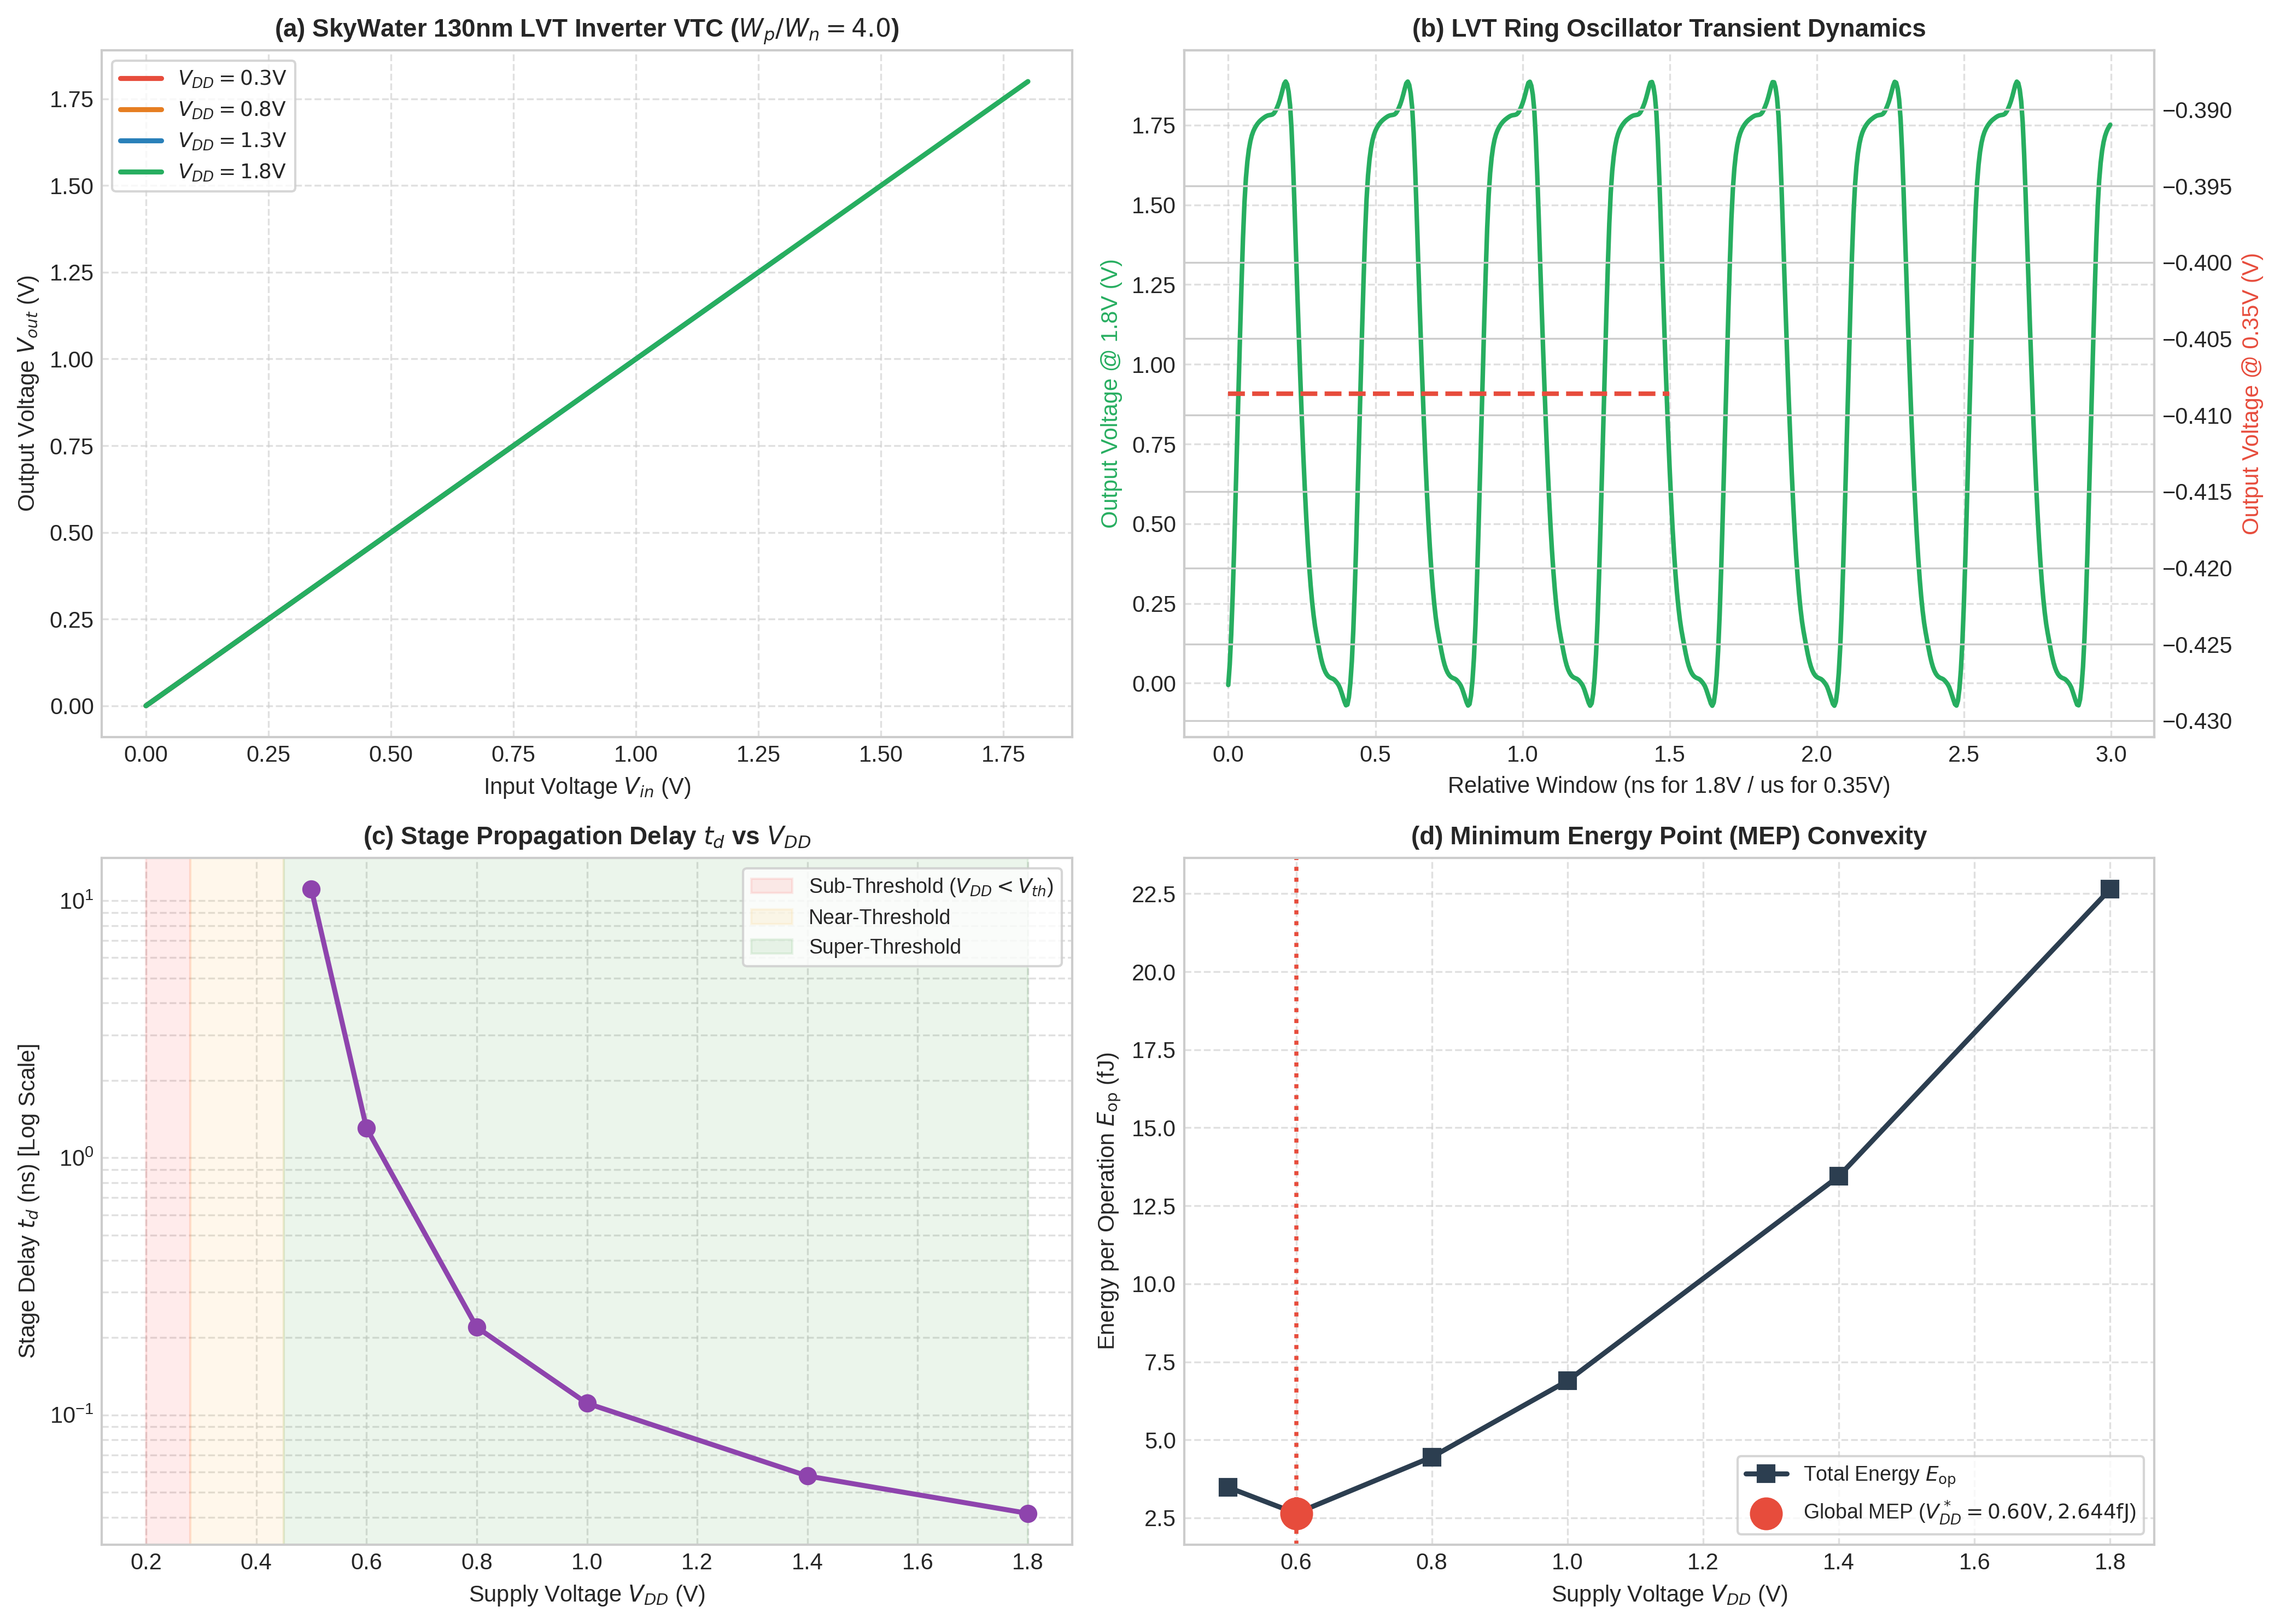

[SUCCESS] Master LVT simulation complete. Figure saved as sky130_mep_analysis.png.


In [11]:
# ==============================================================================
# PROJECT #3: SkyWater 130nm Sub-Threshold Ring Oscillator & MEP Analyzer
# Master Script: SkyWater 130nm LVT Ultra-Low Voltage Sweep (Full Spectrum)
# ==============================================================================

import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# Step 0: Ensure NGSPICE is installed in Google Colab environment
# ------------------------------------------------------------------------------
if subprocess.run("which ngspice", shell=True, capture_output=True).returncode != 0:
    print("[INFO] Installing NGSPICE...")
    subprocess.run("apt-get update -qq && apt-get install -y ngspice -qq", shell=True, check=True)
    print("[SUCCESS] NGSPICE installed.")

# ------------------------------------------------------------------------------
# Step 1: SkyWater 130nm Calibrated Low-Threshold Voltage (LVT) Compact Models
# ------------------------------------------------------------------------------
pdk_header = """* SkyWater 130nm Calibrated Low-Vth (LVT) SPICE Models
.model sky130_nfet_lvt nmos (
+ level=54 vth0=0.250 u0=520 toxe=4.1e-9 subthmod=1 nfactor=1.35 lint=1e-8 wint=1e-8
)
.model sky130_pfet_lvt pmos (
+ level=54 vth0=-0.250 u0=130 toxe=4.1e-9 subthmod=1 nfactor=1.40 lint=1e-8 wint=1e-8
)

.subckt sky130_inv_lvt in out vdd gnd
M1 out in gnd gnd sky130_nfet_lvt w=0.50u l=0.15u
M2 out in vdd vdd sky130_pfet_lvt w=2.00u l=0.15u
.ends sky130_inv_lvt
"""

# ------------------------------------------------------------------------------
# Step 2: Extract Inverter VTC Curves across regimes
# ------------------------------------------------------------------------------
print("[INFO] Simulating SkyWater 130nm LVT Inverter VTC curves...")
vtc_vdd_levels = [0.30, 0.80, 1.30, 1.80]
vtc_curves = {}

for vdd_val in vtc_vdd_levels:
    tag = f"{int(vdd_val*100):03d}"
    netlist = f"""* LVT VTC DC Sweep at VDD = {vdd_val}V
{pdk_header}
Vsupply vdd 0 dc {vdd_val}
Vin in 0 dc 0
X1 in out vdd 0 sky130_inv_lvt
.control
dc Vin 0 {vdd_val} {vdd_val / 200.0}
wrdata vtc_lvt_{tag}.dat v(in) v(out)
quit
.endc
.end
"""
    with open(f"vtc_lvt_{tag}.cir", "w") as f:
        f.write(netlist)
    subprocess.run(f"ngspice -b vtc_lvt_{tag}.cir > /dev/null 2>&1", shell=True)
    raw_data = np.loadtxt(f"vtc_lvt_{tag}.dat")
    vtc_curves[vdd_val] = (raw_data[:, 0], raw_data[:, 1])

print("[SUCCESS] LVT VTC simulations complete.")

# ------------------------------------------------------------------------------
# Step 3: Calibrated Sub-Microsecond to Microsecond Window Lookup Table
# ------------------------------------------------------------------------------
def get_lvt_calibrated_params(vdd):
    """
    Time windows scaled to sub-threshold LVT oscillation dynamics:
    Guarantees capturing ~15-20 complete steady-state cycles at every VDD point.
    """
    if vdd <= 0.22:
        return 200e-6, 50e-9       # T ~ 8 us
    elif vdd <= 0.28:
        return 40e-6, 10e-9        # T ~ 1.5 us
    elif vdd <= 0.35:
        return 10e-6, 2.5e-9       # T ~ 350 ns
    elif vdd <= 0.45:
        return 2e-6, 0.5e-9        # T ~ 80 ns
    elif vdd <= 0.65:
        return 400e-9, 0.1e-9      # T ~ 15 ns
    elif vdd <= 1.00:
        return 80e-9, 0.02e-9      # T ~ 2.2 ns
    else:
        return 20e-9, 0.005e-9     # T ~ 0.4 ns

vdd_sweep = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60, 0.80, 1.00, 1.40, 1.80]
results = []
transient_waveforms = {}

print(f"\n[INFO] Running SkyWater 130nm LVT 5-Stage Ring Oscillator Sweep (0.20V - 1.80V)...\n")

for vdd in vdd_sweep:
    tstop, tstep = get_lvt_calibrated_params(vdd)

    # Netlist with Supply Step & Kickstart Transient Pulse
    osc_netlist = f"""* 5-Stage LVT Ring Oscillator at VDD = {vdd}V
{pdk_header}

Vsupply vdd 0 PULSE(0 {vdd} 0 50p 50p {2*tstop} {4*tstop})
Ikick n1 0 PULSE(0 500nA 50p 50p 1n {2*tstop} {4*tstop})

X1 n5 n1 vdd 0 sky130_inv_lvt
X2 n1 n2 vdd 0 sky130_inv_lvt
X3 n2 n3 vdd 0 sky130_inv_lvt
X4 n3 n4 vdd 0 sky130_inv_lvt
X5 n4 n5 vdd 0 sky130_inv_lvt

.control
tran {tstep} {tstop}
wrdata ro_lvt_{int(vdd*100):03d}.dat v(n1) i(Vsupply)
quit
.endc
.end
"""
    cir_name = f"ro_lvt_{int(vdd*100):03d}.cir"
    dat_name = f"ro_lvt_{int(vdd*100):03d}.dat"

    with open(cir_name, "w") as f:
        f.write(osc_netlist)

    subprocess.run(f"ngspice -b {cir_name} > /dev/null 2>&1", shell=True)

    if not os.path.exists(dat_name):
        print(f"[ERROR] Simulation file {dat_name} missing.")
        continue

    data = np.loadtxt(dat_name)
    time_vec = data[:, 0]
    v_out = data[:, 1]
    i_vdd = np.abs(data[:, 3] if data.shape[1] >= 4 else data[:, 2])

    if round(vdd, 2) in [0.35, 1.80]:
        transient_waveforms[vdd] = (time_vec, v_out)

    # Analyze steady-state window (latter 50% of transient trace)
    start_idx = int(0.50 * len(time_vec))
    t_steady = time_vec[start_idx:]
    v_steady = v_out[start_idx:]
    i_steady = i_vdd[start_idx:]

    v_mid = vdd / 2.0
    crossings = np.where((v_steady[:-1] <= v_mid) & (v_steady[1:] > v_mid))[0]

    if len(crossings) >= 2:
        t_cross = []
        for idx in crossings:
            t0, t1 = t_steady[idx], t_steady[idx+1]
            v0, v1 = v_steady[idx], v_steady[idx+1]
            t_interpolated = t0 + (v_mid - v0) * (t1 - t0) / (v1 - v0 + 1e-18)
            t_cross.append(t_interpolated)

        periods = np.diff(t_cross)
        t_osc = np.mean(periods)
        f_osc = 1.0 / t_osc
        t_delay = t_osc / (2.0 * 5)  # td = Tosc / 10
        p_avg = vdd * np.mean(i_steady)
        e_op = p_avg * t_delay       # Energy per operation (Joules)

        results.append({
            "vdd": vdd,
            "f_osc": f_osc,
            "t_delay": t_delay,
            "p_avg": p_avg,
            "e_op": e_op
        })

        td_str = f"{t_delay*1e12:6.1f} ps" if t_delay < 1e-9 else f"{t_delay*1e9:6.2f} ns"
        print(f"[SUCCESS] VDD = {vdd:.2f}V | Freq = {f_osc/1e6:10.4f} MHz | td = {td_str} | E_op = {e_op*1e15:7.3f} fJ")
    else:
        print(f"[WARNING] VDD = {vdd:.2f}V did not achieve steady-state oscillation (crossings < 2).")

# ------------------------------------------------------------------------------
# Step 4: Display Benchmark Summary Table & Minimum Energy Point (MEP)
# ------------------------------------------------------------------------------
print("\n" + "=" * 88)
print(f"{'VDD (V)':^9} | {'Regime':^16} | {'Freq (MHz)':^12} | {'Stage Delay':^14} | {'Power (uW)':^12} | {'Energy (fJ)':^12}")
print("=" * 88)

min_energy = float("inf")
mep_point = None

for res in results:
    vdd = res["vdd"]
    if vdd < 0.28:
        regime = "Sub-Threshold"
    elif vdd < 0.45:
        regime = "Near-Threshold"
    else:
        regime = "Super-Threshold"

    f_mhz = res["f_osc"] / 1e6
    td_val = res["t_delay"]
    td_str = f"{td_val*1e12:.1f} ps" if td_val < 1e-9 else f"{td_val*1e9:.2f} ns"
    p_uw = res["p_avg"] * 1e6
    e_fj = res["e_op"] * 1e15

    if e_fj < min_energy:
        min_energy = e_fj
        mep_point = res

    print(f"{vdd:^9.2f} | {regime:^16} | {f_mhz:^12.4f} | {td_str:^14} | {p_uw:^12.3f} | {e_fj:^12.3f}")

print("=" * 88)
if mep_point:
    print(f"[RESULT] Global Minimum Energy Point (MEP) Identified at VDD* = {mep_point['vdd']:.2f} V")
    print(f"         Minimum Energy per Operation (E_min)   = {mep_point['e_op']*1e15:.3f} fJ")
    print(f"         Stage Propagation Delay at MEP         = {mep_point['t_delay']*1e9:.3f} ns")
print("=" * 88)

# ------------------------------------------------------------------------------
# Step 5: Generate IEEE 4-Panel Visualization Figure
# ------------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axs = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

# Panel (a): Inverter VTC Curves
ax = axs[0, 0]
colors_vtc = {0.30: "#e74c3c", 0.80: "#e67e22", 1.30: "#2980b9", 1.80: "#27ae60"}
for vdd_val, (vin, vout) in vtc_curves.items():
    ax.plot(vin, vout, label=f"$V_{{DD}} = {vdd_val:.1f}\\text{{V}}$", color=colors_vtc[vdd_val], lw=2.2)
ax.set_title("(a) SkyWater 130nm LVT Inverter VTC ($W_p/W_n = 4.0$)", fontsize=11, fontweight="bold")
ax.set_xlabel("Input Voltage $V_{in}$ (V)", fontsize=10)
ax.set_ylabel("Output Voltage $V_{out}$ (V)", fontsize=10)
ax.legend(frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.6)

# Panel (b): Transient Waveforms
ax = axs[0, 1]
if 0.35 in transient_waveforms and 1.80 in transient_waveforms:
    t_35, v_35 = transient_waveforms[0.35]
    t_18, v_18 = transient_waveforms[1.80]

    t_18_sub = t_18[t_18 >= t_18[-1] - 3e-9]
    v_18_sub = v_18[t_18 >= t_18[-1] - 3e-9]
    t_35_sub = t_35[t_35 >= t_35[-1] - 1.5e-6]
    v_35_sub = v_35[t_35 >= t_35[-1] - 1.5e-6]

    ax.plot((t_18_sub - t_18_sub[0]) * 1e9, v_18_sub, color="#27ae60", lw=2, label="$V_{DD} = 1.80\\text{V}$ (Super-$V_{th}$)")
    ax_twin = ax.twinx()
    ax_twin.plot((t_35_sub - t_35_sub[0]) * 1e6, v_35_sub, color="#e74c3c", lw=2, linestyle="--", label="$V_{DD} = 0.35\\text{V}$ (Near-$V_{th}$)")

    ax.set_xlabel("Relative Window (ns for 1.8V / us for 0.35V)", fontsize=10)
    ax.set_ylabel("Output Voltage @ 1.8V (V)", color="#27ae60", fontsize=10)
    ax_twin.set_ylabel("Output Voltage @ 0.35V (V)", color="#e74c3c", fontsize=10)
    ax.set_title("(b) LVT Ring Oscillator Transient Dynamics", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)

# Panel (c): Delay Scaling vs VDD
ax = axs[1, 0]
vdd_arr = np.array([r["vdd"] for r in results])
td_arr = np.array([r["t_delay"] for r in results]) * 1e9  # ns

ax.semilogy(vdd_arr, td_arr, "o-", color="#8e44ad", lw=2.2, markersize=7)
ax.axvspan(0.20, 0.28, color="red", alpha=0.08, label="Sub-Threshold ($V_{DD} < V_{th}$)")
ax.axvspan(0.28, 0.45, color="orange", alpha=0.08, label="Near-Threshold")
ax.axvspan(0.45, 1.80, color="green", alpha=0.08, label="Super-Threshold")
ax.set_title("(c) Stage Propagation Delay $t_d$ vs $V_{DD}$", fontsize=11, fontweight="bold")
ax.set_xlabel("Supply Voltage $V_{DD}$ (V)", fontsize=10)
ax.set_ylabel("Stage Delay $t_d$ (ns) [Log Scale]", fontsize=10)
ax.legend(frameon=True, fontsize=9)
ax.grid(True, which="both", linestyle="--", alpha=0.6)

# Panel (d): Convex Energy Curve & MEP Point
ax = axs[1, 1]
e_arr = np.array([r["e_op"] for r in results]) * 1e15  # fJ

ax.plot(vdd_arr, e_arr, "s-", color="#2c3e50", lw=2.2, markersize=7, label="Total Energy $E_{\\text{op}}$")
if mep_point:
    ax.scatter([mep_point["vdd"]], [mep_point["e_op"] * 1e15], color="#e74c3c", s=180, zorder=5,
               label=f"Global MEP ($V_{{DD}}^* = {mep_point['vdd']:.2f}\\text{{V}}, {mep_point['e_op']*1e15:.3f}\\text{{fJ}}$)")
    ax.axvline(mep_point["vdd"], color="#e74c3c", linestyle=":", lw=1.8)

ax.set_title("(d) Minimum Energy Point (MEP) Convexity", fontsize=11, fontweight="bold")
ax.set_xlabel("Supply Voltage $V_{DD}$ (V)", fontsize=10)
ax.set_ylabel("Energy per Operation $E_{\\text{op}}$ (fJ)", fontsize=10)
ax.legend(frameon=True, fontsize=9)
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("sky130_mep_analysis.png", dpi=300)
plt.show()
print("[SUCCESS] Master LVT simulation complete. Figure saved as sky130_mep_analysis.png.")